# One-step MPC results

**Complete** · queue · ETA 0h 00m 00s   
Updated 2026-11-10 10:19:11 Västeuropa, normaltid · PID 21124 · 17.33 GiB free  
Selected objective O5

O5 minimizes predicted change in rolling-bank reconstruction loss using online IDBD. The bank starts with the last 128 calibration frames and admits every 16th online frame, replacing the oldest entry after the action and its paired measurement.



## Reconstruction loss and RankMe during training

Each point averages up to 1,000 checkpointed pre-action measurements. Loss is masked-patch MSE. RankMe is measured on unmasked encoder embeddings from the rolling bank. The vertical line at 8,000 images marks the shared calibration checkpoint for each seed.

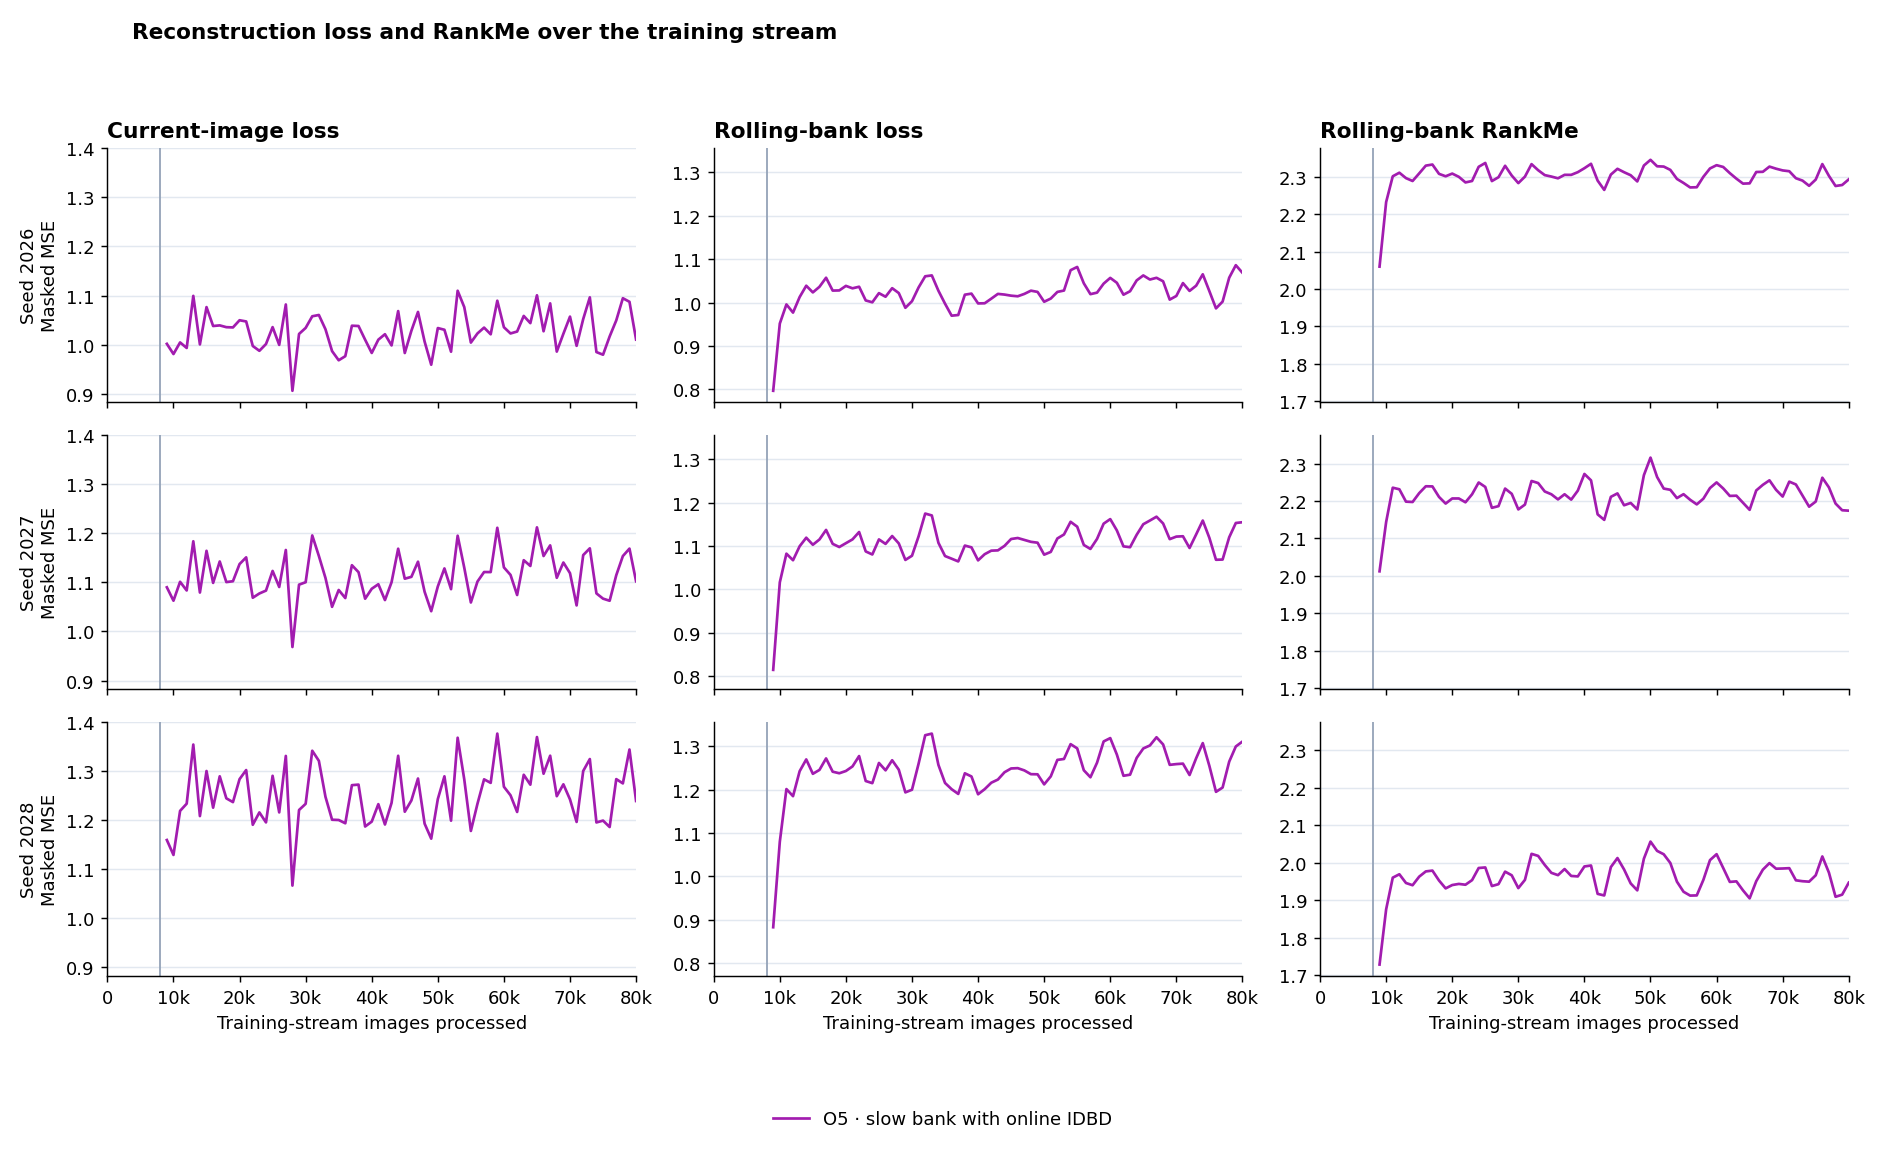

Run the watcher cell at the bottom for live plots while this notebook is open.

## Validation and held-out outcomes

| Split | Seed | Arm | MAE loss | RankMe | Variance | Probe acc. | Balanced acc. | Train updates | Peak GPU MiB |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | Validation | 2026 | slow-bank-idbd | 1.02247 | 2.347 | 0.22279 | 97.38% | 97.38% | 0 | 47.2 | 
 | Validation | 2027 | slow-bank-idbd | 1.11176 | 2.255 | 0.13924 | 97.22% | 97.22% | 0 | 54.8 | 
 | Validation | 2028 | slow-bank-idbd | 1.24962 | 2.014 | 0.04382 | 97.36% | 97.36% | 44 | 71.1 | 
 | Test | 2026 | test-slow-bank-idbd | 1.02373 | 2.335 | 0.21206 | 98.58% | 98.60% |  |  | 
 | Test | 2027 | test-slow-bank-idbd | 1.11594 | 2.245 | 0.13090 | 98.43% | 98.46% |  |  | 
 | Test | 2028 | test-slow-bank-idbd | 1.25583 | 1.991 | 0.04126 | 98.61% | 98.63% |  |  | 

## Prequential next-state RMSE

Balanced matched rows are shared by all predictors. Early and late refer to the first and last quarter of each online trajectory.

| Seed | Arm | Predictor | Window | Images | current_loss | bank_loss | rankme | variance | Normalized RMSE | Update seconds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
 | 2026 | slow-bank-idbd | idbd | all | 72000 | 0 | 0 | 0 | 0 | 0 | 0 | 
 | 2026 | slow-bank-idbd | idbd | early | 18000 | 0 | 0 | 0 | 0 | 0 |  | 
 | 2026 | slow-bank-idbd | idbd | late | 18000 | 0 | 0 | 0 | 0 | 0 |  | 
 | 2027 | slow-bank-idbd | idbd | all | 72000 | 0 | 0 | 0 | 0 | 0 | 0 | 
 | 2027 | slow-bank-idbd | idbd | early | 18000 | 0 | 0 | 0 | 0 | 0 |  | 
 | 2027 | slow-bank-idbd | idbd | late | 18000 | 0 | 0 | 0 | 0 | 0 |  | 
 | 2028 | slow-bank-idbd | idbd | all | 72000 | 0.0001967 | 0.0001063 | 5.607e-05 | 5.469e-06 | 0.02307 | 0.003298 | 
 | 2028 | slow-bank-idbd | idbd | early | 18000 | 0.0003826 | 0.0002099 | 0.0001121 | 1.093e-05 | 0.0454 |  | 
 | 2028 | slow-bank-idbd | idbd | late | 18000 | 0 | 0 | 0 | 0 | 0 |  | 

In [ ]:
# Run this cell to watch the training curves. Interrupt it to stop watching.
from IPython.display import Image, clear_output, display
from pathlib import Path
import json, time

chart_path = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\slow-bank\\training-curves.png')
status_path = chart_path.with_name('status.json')
while True:
    try:
        status = json.loads(status_path.read_text(encoding='utf-8'))
        png = chart_path.read_bytes()
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    display(Image(data=png))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)
